Week 5: Model Comparison

This notebook evaluates Decision Tree and Random Forest against Linear Regression baseline. Decision Tree and Random Forest regressors were selected to evaluate whether nonlinear models could improve property-price predictions compared with the Linear Regression baseline. These models were chosen because Decision Tree can capture complex relationships between property features and prices, while Random Forest combines multiple trees to improve predictive accuracy and reduce overfitting. These models will be evaluated aganist the baseline using $R^2$, MAE, RMSE, Median Absolute Error, and MDAPE. Training and validation performance will also be compared to assess generalization and identify overfitting.  

In [1]:
from pathlib import Path
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import category_encoders as ce
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, median_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

In [2]:
path_dir = Path("raw")
files = sorted(path_dir.glob("CRMLSSold*.csv"))
train_files = files[:-1]
test_file = files[-1]

train_list = [pd.read_csv(file, low_memory=False) for file in train_files]
df = pd.concat(train_list, ignore_index=True)

test_df = pd.read_csv(test_file, low_memory=False)

print(f"Training Period: {train_files[0].name} to {train_files[-1].name}") 
print(f"Test file: {test_file.name}")

print("The combined shape of Train DataFrame is:", df.shape)
print("Test shape:", test_df.shape)


Training Period: CRMLSSold202502.csv to CRMLSSold202607.csv
Test file: CRMLSSold202608.csv
The combined shape of Train DataFrame is: (400050, 80)
Test shape: (23131, 79)


In [3]:
df_scoped = df[
        (df['PropertyType'] == 'Residential') & 
        (df['PropertySubType'] == 'SingleFamilyResidence')].copy()
print("The shape of scoped DataFrame is:", df_scoped.shape)


The shape of scoped DataFrame is: (201413, 80)


In [4]:
# Determine the percentage of null values for each feature.
null_rates = (df_scoped.isnull().mean()*100).round(2)
print(null_rates[null_rates > 0].sort_values(ascending=False))

TaxYear                   100.00
BusinessType              100.00
FireplacesTotal           100.00
AboveGradeFinishedArea    100.00
TaxAnnualAmount           100.00
                           ...  
ListAgentFullName           0.03
ListAgentAOR                0.02
BathroomsTotalInteger       0.01
ListAgentLastName           0.01
PurchaseContractDate        0.01
Length: 62, dtype: float64


Data Preprocessing:

1. Remove exact duplicate rows
2. Remove rows with missing close dates or close dates later than the selected cutoff date.
3. Remove latitude and longitude values outside the defined geographic boundaries.
4. Missing values in GarageSpaces were filled with 0, assuming that a missing value indicates the property has no garage.
5. Rows containing zero were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, and Longitude.
6. Rows containing null were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, Longitude, PostalCode, and City
7. Replace zero values in LotSizeSquareFeet with NaN which will be handled later using median imputation.

In [5]:
rows_before = len(df_scoped)
df_scoped['CloseDate'] = pd.to_datetime(df_scoped['CloseDate'].astype(str), errors='coerce')
cutoff_date = pd.Timestamp('2026-07-31')

# Count rows where CloseDate is null or greater than cutoff_date
df_scoped = df_scoped[
    df_scoped['CloseDate'].notna() & (df_scoped['CloseDate'] <= cutoff_date)
    ].copy()

# Find rows where all the values are duplicate
all_dup_count = df_scoped.duplicated().sum()
print(f"Exact duplicate rows (entire row matches): {all_dup_count}")

df_scoped = df_scoped.drop_duplicates(keep='first')
rows_removed = rows_before - len(df_scoped)
print(f"Total rows removed: {rows_removed}")

Exact duplicate rows (entire row matches): 6
Total rows removed: 6


In [6]:
numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "ClosePrice", 
            "Latitude", "Longitude","LotSizeSquareFeet", "YearBuilt",
            "Stories", "GarageSpaces"]

categorical_features = ["PostalCode", "City", "CountyOrParish"] 
                        
binary_features = ["NewConstructionYN", "PoolPrivateYN", "ViewYN", 
            "FireplaceYN"]

features = numeric_features + categorical_features + binary_features

for col in numeric_features:
    if col in df_scoped.columns:
        df_scoped[col] = pd.to_numeric(df_scoped[col], errors='coerce')

# Define valid coordinate ranges for California
rows_before = len(df_scoped)
lat_min, lat_max = 32.0, 42.0
lon_min, lon_max = -124.0, -114.0

# Identify rows with invalid or out-of-bounds coordinates
invalid_lat = (df_scoped['Latitude'] < lat_min) | (df_scoped['Latitude'] > lat_max)
invalid_lon = (df_scoped['Longitude'] < lon_min) | (df_scoped['Longitude'] > lon_max)
invalid_location_count = (invalid_lat | invalid_lon).sum()

print(f"Rows with out-of-bounds coordinates: {invalid_location_count}")

# Drop rows outside these bounds
df_scoped = df_scoped[~(invalid_lat | invalid_lon)].copy()
rows_removed = rows_before - (len(df_scoped))
pct_removed = (rows_removed / rows_before) * 100 if rows_before > 0 else 0

print(f"Total rows before: {rows_before}")
print(f"Total rows removed: {rows_removed} ({pct_removed:.2f}%)")


Rows with out-of-bounds coordinates: 61
Total rows before: 201407
Total rows removed: 61 (0.03%)


In [7]:
df_model = df_scoped[features].copy()
before = len(df_model)


# Drop ClosePrice and LivingArea 0 and less
df_model = df_model[
            (df_model["ClosePrice"] > 0) & (df_model["LivingArea"] > 0) &
            (df_model["BedroomsTotal"] > 0) & (df_model["BathroomsTotalInteger"] > 0) &
            (df_model["Latitude"] != 0) & (df_model["Longitude"] != 0) & 
            (df_model["YearBuilt"] >= 1900) & (df_model["YearBuilt"] <= 2026)
             ].copy()

# Drop null values
df_model = df_model.dropna(subset=["ClosePrice", "BedroomsTotal", "BathroomsTotalInteger",
                                   "LivingArea", "Latitude", "Longitude", "City", "PostalCode", "YearBuilt"]).copy()

# Fill null garagespaces with 0
df_model["GarageSpaces"] = df_model["GarageSpaces"].fillna(0)

# Fill zero values in LotSizeSquareFeet with Nan
df_model["LotSizeSquareFeet"] = df_model["LotSizeSquareFeet"].replace(0, np.nan)

print(f'After Filtering:{df_model.shape}')

print(f"Removed {before - len(df_model)} rows "
    f"({(before-len(df_model)) / before * 100:.2f}%)")


After Filtering:(199996, 17)
Removed 1350 rows (0.67%)


Checks:
1.  Check all numerical and categorical features for zero and missing values
2.  Check for duplicates across entire row

In [8]:
results=[]
for col in features:
    if col in df_model.columns:
        results.append({
            "Columns": col,
            "Zero Count": (df_model[col] == 0).sum(),
            "Null Count": df_model[col].isnull().sum()
        }) 
summary = pd.DataFrame(results)
print(summary.to_string(index=False))
print("Total Zero Count:", summary["Zero Count"].sum())
print("Total Null count:", summary["Null Count"].sum())

              Columns  Zero Count  Null Count
           LivingArea           0           0
        BedroomsTotal           0           0
BathroomsTotalInteger           0           0
           ClosePrice           0           0
             Latitude           0           0
            Longitude           0           0
    LotSizeSquareFeet           0        3532
            YearBuilt           0           0
              Stories           0       20915
         GarageSpaces       23130           0
           PostalCode           0           0
                 City           0           0
       CountyOrParish           0           0
    NewConstructionYN      177730       15330
        PoolPrivateYN      153425       15317
               ViewYN       69531       18204
          FireplaceYN       54343         139
Total Zero Count: 478159
Total Null count: 73437


In [9]:
# Split the dataset into training and validation set
df = df_model.copy()
X = df.drop(columns = ["ClosePrice"])
y = df["ClosePrice"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)


Removing Extreme Outliers from Training and Validation Datasets
1. ClosePrice was filtered using 0.01st and 99.999th percentile, with an additional upper limit of $50 million.
2. For Living Area and LotSizeSquareFeet was filtered using 0.01st and 99.999th percentile.
3. For BedroomTotal and BathroomsTotalInteger only upper threshold were applied since the zero were already removed in the previous step. 

In [10]:
X_train = X_train.copy()
X_val = X_val.copy()

y_train = pd.Series(y_train, index=X_train.index)
y_val = pd.Series(y_val, index=X_val.index)

# Quantile settings
lower_q = 0.0005
upper_q = 0.9999

# Features to filter on both ends
two_sided_cols = ["LivingArea","LotSizeSquareFeet"]

# Features to filter only at the upper end
upper_only_cols = ["BedroomsTotal","BathroomsTotalInteger"]

# 1. Filter ClosePrice using lower and upper quantiles
price_lower = y_train.quantile(lower_q)
price_upper = min(y_train.quantile(upper_q), 50000000)

train_price_mask = y_train.between(price_lower, price_upper)
val_price_mask = y_val.between(price_lower, price_upper)

X_train = X_train.loc[train_price_mask].copy()
y_train = y_train.loc[train_price_mask].copy()

X_val = X_val.loc[val_price_mask].copy()
y_val = y_val.loc[val_price_mask].copy()

# 2. Calculate feature thresholds using training data only
lower_bounds = X_train[two_sided_cols].quantile(lower_q)
upper_bounds = X_train[two_sided_cols + upper_only_cols].quantile(upper_q)

# 3. Filter lower and upper ends for LivingArea and LotSizeSquareFeet
for col in two_sided_cols:
    train_mask = X_train[col].between(lower_bounds[col], upper_bounds[col])
    val_mask = X_val[col].between(lower_bounds[col], upper_bounds[col])

    X_train = X_train.loc[train_mask].copy()
    y_train = y_train.loc[train_mask].copy()

    X_val = X_val.loc[val_mask].copy()
    y_val = y_val.loc[val_mask].copy()

# 4. Filter only the upper end for bedrooms and bathrooms
for col in upper_only_cols:
    train_mask = X_train[col] <= upper_bounds[col]
    val_mask = X_val[col] <= upper_bounds[col]

    X_train = X_train.loc[train_mask].copy()
    y_train = y_train.loc[train_mask].copy()

    X_val = X_val.loc[val_mask].copy()
    y_val = y_val.loc[val_mask].copy()

# 5. Report results
print(f"Price lower threshold: ${price_lower:,.2f}")
print(f"Price upper threshold: ${price_upper:,.2f}")

print("\nFeature thresholds:")
print(pd.DataFrame({
    "Lower": lower_bounds,
    "Upper": upper_bounds
}).to_string(float_format=lambda x: f"{x:,.2f}"))

print("Remaining training rows:", len(X_train))
print("Remaining validation rows:", len(X_val))

Price lower threshold: $70,000.00
Price upper threshold: $50,000,000.00

Feature thresholds:
                       Lower          Upper
BathroomsTotalInteger    NaN          14.00
BedroomsTotal            NaN          11.01
LivingArea            457.90      15,000.15
LotSizeSquareFeet       0.14 877,054,159.08
Remaining training rows: 156882
Remaining validation rows: 39216


Median Target Encoding:

Median target encoding is applied to the geographic features PostalCode, City, and CountyOrParish. Each category is represented by the median property sale price associted with it. 


In [11]:
X_train = X_train.copy()
X_val = X_val.copy()
y_train = y_train.copy()
y_val = y_val.copy()

# Geographic columns used for median-price encoding
target_cols = ["PostalCode", "City", "CountyOrParish"]

median_feature_map = {
    "PostalCode": "postalcode_median_price",
    "City": "city_median_price",
    "CountyOrParish": "county_median_price"
}


median_features = list(median_feature_map.values())

# Preserve original geographic features for encoding
X_train_original = X_train.copy()
X_val_original = X_val.copy()

# Fallback for missing/unseen geographic categories
global_median = y_train.median()

kf = KFold(n_splits=5, shuffle=True,random_state=42)

# Initialize median-price features
for feature in median_features:
    X_train[feature] = np.nan

for train_idx, val_idx in kf.split(X_train_original):

    X_fold_train = X_train_original.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    
    X_fold_val = X_train_original.iloc[val_idx]

    for col, feature in median_feature_map.items():
        medians = y_fold_train.groupby(X_fold_train[col]).median()
        encoded_values = X_fold_val[col].map(medians)

        X_train.iloc[val_idx,X_train.columns.get_loc(feature)] = encoded_values.to_numpy()

# Fill missing/unseen categories with the global training median
X_train[median_features] = (X_train[median_features].fillna(global_median))

# Fit category medians using all training targets only
for col, feature in median_feature_map.items():
    medians = y_train.groupby(X_train_original[col]).median()
    X_val[feature] = (X_val_original[col].map(medians).fillna(global_median))


In [12]:
geo_cols_to_use = ["City"]

median_features_to_use = [median_feature_map[col] for col in geo_cols_to_use]

# Binary features in the dataset
bool_cols = binary_features.copy()
numeric_cols = numeric_features.copy()
categorical_cols = categorical_features.copy()

# Remove original geographic columns from model feature lists
numeric_cols = [col for col in numeric_cols if col not in target_cols]

categorical_cols = [col for col in categorical_cols if col not in target_cols]

# Add median-price features to numeric features
numeric_cols = list(dict.fromkeys(numeric_cols + median_features_to_use))

# Add City and CountyOrParsh as categorical features
categorical_cols = list(dict.fromkeys(categorical_cols + ["PostalCode", "CountyOrParish"]))

# Only retain binary features present in the data
bool_cols = [col for col in bool_cols if col in X_train.columns]

# Ensure binary features are not also in numeric/categorical lists
numeric_cols = [col for col in numeric_cols if col not in bool_cols]

categorical_cols = [col for col in categorical_cols if col not in bool_cols]

# Remove original geographic columns after encoding
X_train = X_train.drop(columns=["City"], errors="ignore")
X_val = X_val.drop(columns=["City"], errors="ignore")

# Ensure train and validation have matching columns and order
X_val = X_val.reindex(columns=X_train.columns)

In [13]:
# Convert binary features into a consistent numerical format
bool_mapping = {
    True: 1,
    False: 0,
    "True": 1,
    "False": 0,
    "true": 1,
    "false": 0,
    "Unknown": np.nan,
    "unknown": np.nan,
    "": np.nan
}

for col in bool_cols:
    X_train[col] = pd.to_numeric(
        X_train[col].map(lambda x: bool_mapping.get(x, np.nan)
            if pd.notna(x) else np.nan), errors="coerce")

    X_val[col] = pd.to_numeric(
        X_val[col].map(lambda x: bool_mapping.get(x, np.nan)
            if pd.notna(x) else np.nan), errors="coerce")


In [14]:
# check if feature lists contains only columns that are present in the training dataset
numeric_cols = [col for col in numeric_cols if col in X_train.columns]

bool_cols = [col for col in bool_cols if col in X_train.columns]

categorical_cols = [col for col in categorical_cols if col in X_train.columns]

# Print feature lists to verify
print("Numeric columns:", numeric_cols)
print("Boolean columns:", bool_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'Latitude', 'Longitude', 'LotSizeSquareFeet', 'YearBuilt', 'Stories', 'GarageSpaces', 'city_median_price']
Boolean columns: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']
Categorical columns: ['PostalCode', 'CountyOrParish']


In [15]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

boolean_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("boolean", boolean_pipeline, bool_cols),
    ("categorical", categorical_pipeline, categorical_cols)])

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())])

lr_model.fit(X_train, y_train)

y_train_pred = lr_model.predict(X_train)
y_val_pred = lr_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)

def mdape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero = y_true != 0
    if not np.any(nonzero):
        return np.nan
    percentage_errors = (np.abs(y_true[nonzero] - y_pred[nonzero]) / np.abs(y_true[nonzero])) * 100
    return np.median(percentage_errors)

def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred) * 100,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedianAbsoluteError": median_absolute_error(y_true, y_pred),
        "MDAPE": mdape(y_true, y_pred)
    }

train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")



TRAINING REPORT
R2: 73.49%
MAE: $311,411.61
RMSE: $690,957.26
Median Absolute Error: $193,273.92
MDAPE: 20.24%

VALIDATION REPORT
R2: 72.58%
MAE: $314,898.22
RMSE: $696,336.32
Median Absolute Error: $196,232.43
MDAPE: 20.43%


In [16]:
diagnostics = pd.DataFrame({
    "actual": np.asarray(y_val).ravel(),
    "original_pred": np.asarray(y_val_pred).ravel()})

# Evaluate the original model by target range
diagnostics["price_group"] = pd.cut(
    diagnostics["actual"],
    bins=[
        -np.inf,
        1000000,
        3000000,
        10000000,
        50000000,
        np.inf],
    labels=[
        "Under $1M",
        "$1M-$3M",
        "$3M-$10M",
        "$10M-$50M",
        "Over $50M"])

print("\nOriginal model")

for group, data in diagnostics.groupby("price_group", observed=True):
    actual = data["actual"].to_numpy()
    pred = data["original_pred"].to_numpy()

    print(f"\n{group} (n={len(data)})")
    print("MAE:", round(mean_absolute_error(actual, pred), 2))
    print("Median absolute error:", round(median_absolute_error(actual, pred), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, pred)), 2))

    nonzero = actual != 0
    if nonzero.any():
        mdape_value = np.median(np.abs(actual[nonzero] - pred[nonzero]
                                      ) / np.abs(actual[nonzero]) * 100)
        print("MDAPE:", round(mdape_value, 2), "%")

# Count extreme observations in training and validation
print("\nEXTREME VALUE COUNTS")

for name, y in [
    ("Training", y_train),("Validation", y_val)]:
    y = np.asarray(y).ravel()

    print(f"\n{name}:")
    print("Over $10M:", np.sum(y > 10000000))
    print("Over $50M:", np.sum(y > 50000000))
    print("Over $100M:", np.sum(y > 100000000))
    print("Over $500M:", np.sum(y > 500000000))
    


Original model

Under $1M (n=22643)
MAE: 214837.14
Median absolute error: 171359.46
RMSE: 288425.18
MDAPE: 26.86 %

$1M-$3M (n=14418)
MAE: 321323.37
Median absolute error: 216163.24
RMSE: 501561.65
MDAPE: 14.11 %

$3M-$10M (n=2021)
MAE: 952251.09
Median absolute error: 664837.06
RMSE: 1323155.55
MDAPE: 16.15 %

$10M-$50M (n=134)
MAE: 6919042.22
Median absolute error: 5513530.17
RMSE: 8624104.26
MDAPE: 42.9 %

EXTREME VALUE COUNTS

Training:
Over $10M: 540
Over $50M: 0
Over $100M: 0
Over $500M: 0

Validation:
Over $10M: 134
Over $50M: 0
Over $100M: 0
Over $500M: 0


In [17]:
errors = pd.DataFrame({
    "Actual": np.asarray(y_val).ravel(),
    "Predicted": np.asarray(y_val_pred).ravel()
})

errors["AbsoluteError"] = (
    errors["Actual"] - errors["Predicted"]
).abs()

errors["AbsolutePercentageError"] = np.where(
    errors["Actual"] != 0,
    errors["AbsoluteError"]
    / np.abs(errors["Actual"]) * 100,
    np.nan
)

print("\nLARGEST VALIDATION ERRORS")

print(
    errors.sort_values(
        "AbsoluteError", ascending=False
    ).head(20).to_string(index=False)
)


LARGEST VALIDATION ERRORS
    Actual    Predicted  AbsoluteError  AbsolutePercentageError
48500000.0 1.347039e+07   3.502961e+07                72.226006
42000000.0 1.700995e+07   2.499005e+07                59.500123
31750000.0 7.623934e+06   2.412607e+07                75.987610
28500000.0 8.986264e+06   1.951374e+07                68.469248
32000000.0 1.376471e+07   1.823529e+07                56.985269
28000000.0 1.035238e+07   1.764762e+07                63.027222
24500000.0 8.022601e+06   1.647740e+07                67.254691
19750000.0 4.599518e+06   1.515048e+07                76.711303
26000000.0 1.134132e+07   1.465868e+07                56.379551
15991988.0 1.454612e+06   1.453738e+07                90.904120
15649999.0 1.435072e+06   1.421493e+07                90.830211
19850000.0 7.083260e+06   1.276674e+07                64.316069
22100000.0 9.459148e+06   1.264085e+07                57.198425
22000000.0 9.621404e+06   1.237860e+07                56.266346
21250000.0 9.

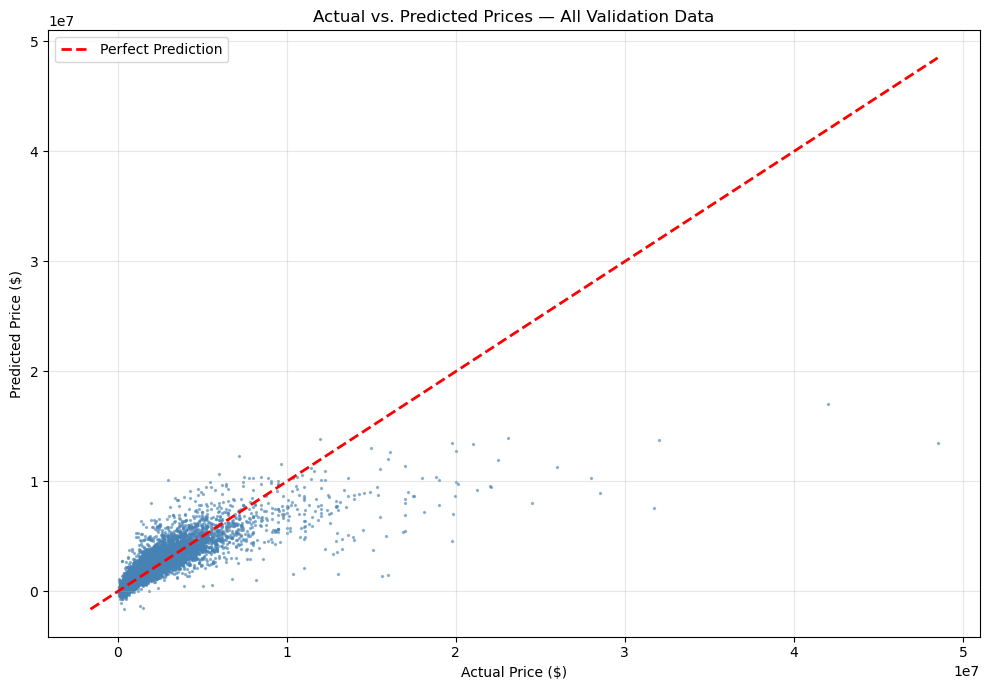

In [18]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Fit the model using the original, unencoded data
dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_val_pred = dt_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)


train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")



TRAINING REPORT
R2: 84.77%
MAE: $228,860.73
RMSE: $523,681.46
Median Absolute Error: $103,096.67
MDAPE: 11.71%

VALIDATION REPORT
R2: 75.32%
MAE: $247,901.72
RMSE: $660,621.38
Median Absolute Error: $104,880.90
MDAPE: 11.95%


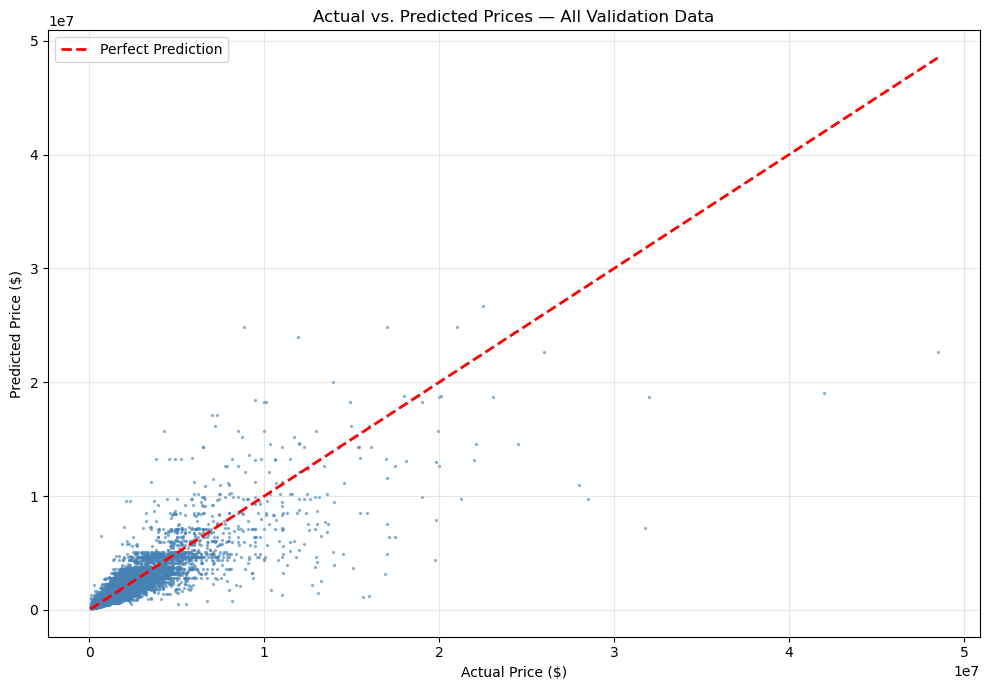

In [20]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split = 20,
        min_samples_leaf = 10,
        max_features = 0.8,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit the model using the original, unencoded data
rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_val_pred = rf_model.predict(X_val)

train_r2 = r2_score(y_train, y_train_pred)
val_r2 = r2_score(y_val, y_val_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

val_mae = mean_absolute_error(y_val, y_val_pred)


train_report = regression_report(y_train, y_train_pred)
val_report = regression_report(y_val, y_val_pred)

print("\nTRAINING REPORT")
print(f"R2: {train_report['R2']:.2f}%")
print(f"MAE: ${train_report['MAE']:,.2f}")
print(f"RMSE: ${train_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${train_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {train_report['MDAPE']:.2f}%")

print("\nVALIDATION REPORT")
print(f"R2: {val_report['R2']:.2f}%")
print(f"MAE: ${val_report['MAE']:,.2f}")
print(f"RMSE: ${val_report['RMSE']:,.2f}")
print(f"Median Absolute Error: ${val_report['MedianAbsoluteError']:,.2f}")
print(f"MDAPE: {val_report['MDAPE']:.2f}%")



TRAINING REPORT
R2: 86.90%
MAE: $174,524.17
RMSE: $485,825.57
Median Absolute Error: $72,369.69
MDAPE: 8.12%

VALIDATION REPORT
R2: 81.05%
MAE: $198,472.04
RMSE: $578,860.38
Median Absolute Error: $78,649.80
MDAPE: 8.90%


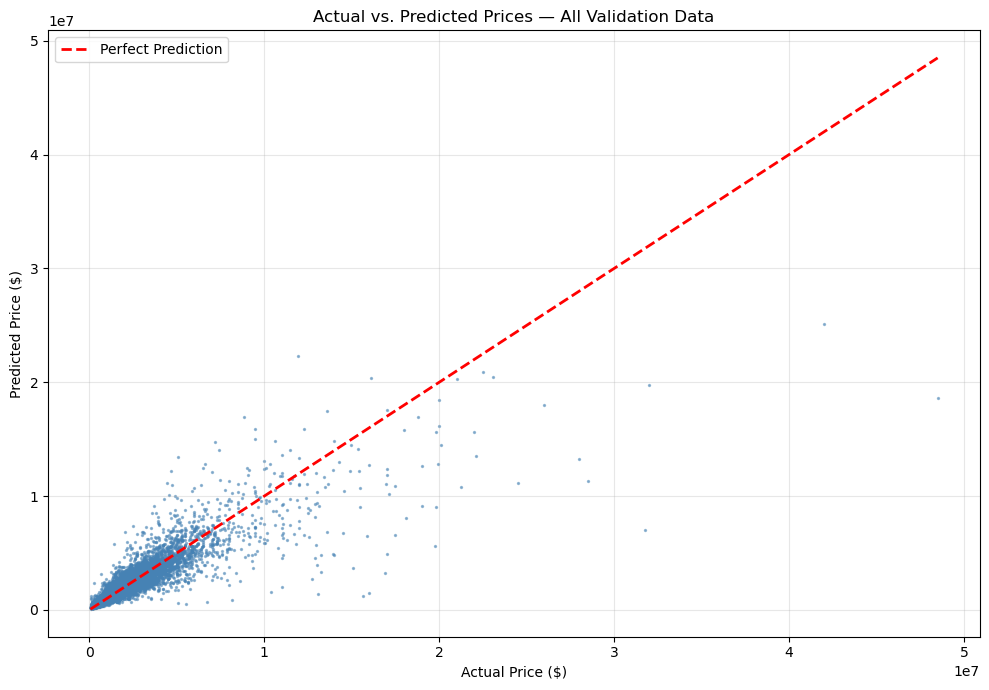

In [22]:
actual = np.asarray(y_val).ravel()
predicted = np.asarray(y_val_pred).ravel()

plt.figure(figsize=(10, 7))

plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

# Perfect prediction line
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs. Predicted Prices — All Validation Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Linear Regression has a small training-validation performance gap, suggesting consistent generalization. It has relatively high prediction errors indicating that it might not capture complex relationship between property characteristics and prices.

Decision Tree captures nonlinear patterns and shows improvement in prediction accuracy over Linear Regression, but it is more prone to overfitting since the patterns do not generalize well to unseen properties.

Random Forest provides the strongest overall predictive performance by capturing complex relationships while reducing the instability of an individual tree. The Random Forest achieves the highest validation $R^2$ of 81.05% and lowest validation MAE among the three models. It's main weakness is that the prediction errors are still high. Overall, it offers the best trade-off between predictive accuray and generalization. 